## Loading the source extracts

The cell below reads every CSV file inside the ZIP archive into a dictionary of DataFrames, using each filename (without `.csv`) as the table key. It reports the number of tables and the dimensions of each extract. If a file is missing or the archive path is incorrect, loading will fail and should be resolved before continuing.

In [1]:
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np

# Path to uploaded stadioequities.zip
zip_path = Path("/Users/kesaobakasithole/stadioequities.zip")

# Read all nine CSV files directly from the stadioequities.zip
with zipfile.ZipFile(zip_path, "r") as z:
    csv_files = sorted(
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    )

    tables = {
        Path(name).stem: pd.read_csv(
            z.open(name),
            dtype={"client_id": "string"}
        )
        for name in csv_files
    }

print("Number of CSV tables:", len(tables))

for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")


Number of CSV tables: 9
1_client_account: 2,110 rows, 9 columns
2_app_web_behaviour: 27,645 rows, 10 columns
3_funding_account_activity: 4,863 rows, 7 columns
4_trading_activity: 4,798 rows, 9 columns
5_product_subscription: 960 rows, 6 columns
6_support_feedback: 1,299 rows, 7 columns
7_marketing_activity: 10,372 rows, 7 columns
8_compliance_monitoring: 130 rows, 5 columns
9_modelling_outcomes: 2,104 rows, 6 columns


In [2]:
# Clean the client_id values and remove exact duplicate rows
for name, df in tables.items():
    if "client_id" not in df.columns:
        raise ValueError(f"{name} does not contain client_id.")

    df["client_id"] = df["client_id"].str.strip()

    # Treat blank IDs as missing
    df["client_id"] = df["client_id"].replace("", pd.NA)

    # Remove records that are identical across every column
    tables[name] = df.drop_duplicates().copy()

# Check missing primary keys
for name, df in tables.items():
    print(f"{name}: {df['client_id'].isna().sum()} missing client IDs")

# Remove records without a join key
for name, df in tables.items():
    tables[name] = df.dropna(subset=["client_id"]).copy()

# The client account table should contain one row per client.
# The six duplicate client IDs in the supplied extract are exact duplicates.
client_account = tables["1_client_account"].drop_duplicates(
    subset=["client_id"],
    keep="first"
).copy()

tables["1_client_account"] = client_account

print("\nUnique clients in client account table:",
      client_account["client_id"].nunique())


1_client_account: 0 missing client IDs
2_app_web_behaviour: 0 missing client IDs
3_funding_account_activity: 0 missing client IDs
4_trading_activity: 0 missing client IDs
5_product_subscription: 0 missing client IDs
6_support_feedback: 0 missing client IDs
7_marketing_activity: 0 missing client IDs
8_compliance_monitoring: 0 missing client IDs
9_modelling_outcomes: 0 missing client IDs

Unique clients in client account table: 2104


In [3]:
def aggregate_by_client(df, prefix, exclude_columns=None):
    """
    Convert a transaction/event-level table into one row per client.
    All generated feature names receive a table-specific prefix.
    """
    exclude_columns = set(exclude_columns or [])
    feature_columns = [
        c for c in df.columns
        if c not in {"client_id"} | exclude_columns
    ]

    work = df[["client_id"] + feature_columns].copy()

    # Identify and convert date/time columns
    datetime_cols = [
        c for c in feature_columns
        if "timestamp" in c.lower() or "date" in c.lower()
    ]

    for col in datetime_cols:
        work[col] = pd.to_datetime(work[col], errors="coerce")

    aggregations = {}

    for col in feature_columns:
        if col in datetime_cols:
            aggregations[col] = ["min", "max"]

        elif pd.api.types.is_numeric_dtype(work[col]) or \
                pd.api.types.is_bool_dtype(work[col]):
            # Acquisition cost is client-level and repeated across
            # campaign rows, so do not sum it.
            if col == "acquisition_cost":
                aggregations[col] = ["mean", "max"]
            else:
                aggregations[col] = ["count", "sum", "mean", "max"]

        else:
            # For categories and text, retain distinct counts and
            # the most frequent value rather than every event.
            aggregations[col] = [
                ("nunique", lambda s: s.nunique(dropna=True)),
                ("mode", lambda s: (
                    s.mode(dropna=True).iloc[0]
                    if not s.mode(dropna=True).empty
                    else pd.NA
                ))
            ]

    # Build a one-row-per-client summary
    grouped = work.groupby("client_id").agg(aggregations)

    # Flatten the generated multi-level column names
    grouped.columns = [
        f"{prefix}_{col}_{stat}"
        for col, stat in grouped.columns
    ]

    return grouped.reset_index()


## Building the consolidated client table

The client-account table provides the base population. Each operational table is aggregated and left-joined on `client_id`; the outcomes table is then joined after checking for duplicate outcome keys. One-to-one validation is used to catch unexpected key relationships. Inspect the final shape and sample rows before proceeding.

In [4]:
# Start with the client profile table
merged_df = tables["1_client_account"].copy()

# Aggregate the seven operational tables
operational_tables = [
    ("2_app_web_behaviour", "app"),
    ("3_funding_account_activity", "funding"),
    ("4_trading_activity", "trading"),
    ("5_product_subscription", "subscription"),
    ("6_support_feedback", "support"),
    ("7_marketing_activity", "marketing"),
    ("8_compliance_monitoring", "compliance"),
]

for table_name, prefix in operational_tables:
    df = tables[table_name]

    # first_deposit_timestamp is also present in the outcomes table.
    # Exclude it here to avoid duplicating the activation-related field.
    exclusions = (
        ["first_deposit_timestamp"]
        if table_name == "3_funding_account_activity"
        else []
    )

    summary = aggregate_by_client(
        df,
        prefix=prefix,
        exclude_columns=exclusions
    )

    # Enforce one row per client before merging
    assert summary["client_id"].is_unique, (
        f"{table_name} summary has duplicate client IDs"
    )

    merged_df = merged_df.merge(
        summary,
        on="client_id",
        how="left",
        validate="one_to_one"
    )

# Merge the modelling outcomes table
outcomes = tables["9_modelling_outcomes"].copy()

# Exact duplicate rows were already removed; the outcomes table
# should have one record per client.
if outcomes["client_id"].duplicated().any():
    raise ValueError(
        "The outcomes table has multiple records per client. "
        "Investigate these before merging."
    )

merged_df = merged_df.merge(
    outcomes,
    on="client_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_outcome")
)

print("Merge completed successfully.")
print("Final dataset shape:", merged_df.shape)
print("Unique clients:", merged_df["client_id"].nunique())
print("Duplicate client IDs:", merged_df["client_id"].duplicated().sum())

display(merged_df.head())


Merge completed successfully.
Final dataset shape: (2104, 120)
Unique clients: 2104
Duplicate client IDs: 0


,client_id,registration_date,kyc_completion_date,kyc_status,acquisition_channel,region,age,stated_goal,risk_appetite,app_event_timestamp_min,...,compliance_alert_type_mode,compliance_alert_disposition_nunique,compliance_alert_disposition_mode,compliance_case_outcome_nunique,compliance_case_outcome_mode,activation_outcome,first_deposit_timestamp,dormancy_outcome,dormancy_timestamp,observation_end_date
0,CL_004000,2025-09-03 22:22:33,2025-09-04 00:36:12,Completed,Paid social,FS,27.0,Retirement,Not stated,2025-09-07 19:24:31,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59
1,CL_004001,2024-04-12 02:09:20,NaN,In Progress,Paid search,GP,34.0,Long-term investing,Moderate,2024-04-19 03:22:35,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59
2,CL_004002,2023-10-15 16:24:14,2023-10-16 02:19:23,Completed,Paid search,LP,25.0,Unknown,Moderate,2023-10-16 14:59:26,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59
3,CL_004003,2024-11-28 04:27:10,2024-11-28 19:03:06,Completed,Influencer,WC,23.0,Retirement,Aggressive,2024-12-01 04:53:18,...,NaN,NaN,NaN,NaN,NaN,True,2024-11-30 04:52:09,False,NaN,2026-08-31 23:59:59
4,CL_004004,2024-04-16 22:31:40,2024-04-16 23:48:27,Completed,Referral,KZN,22.0,Education fund,Aggressive,2024-05-01 13:06:52,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59


### Validate the merged dataset

These checks confirm that each final row has a unique, non-missing client ID. Outcome distributions help establish which labels are available, while the missingness summary highlights columns that may need investigation. The `info()` output provides data types and non-null counts. These checks are structural and should be followed by business-rule validation and a target-leakage review.

In [5]:
# Check key integrity
assert merged_df["client_id"].is_unique
assert merged_df["client_id"].notna().all()

# Check target availability
print("Activation outcomes:")
print(merged_df["activation_outcome"].value_counts(dropna=False))

print("\nDormancy outcomes:")
print(merged_df["dormancy_outcome"].value_counts(dropna=False))

# Review missing values
missing_summary = (
    merged_df.isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"] / len(merged_df) * 100
).round(2)

display(
    missing_summary
    .sort_values("missing_percentage", ascending=False)
    .head(20)
)

# Review dataset structure
merged_df.info()


Activation outcomes:
activation_outcome
False    1288
True      816
Name: count, dtype: int64

Dormancy outcomes:
dormancy_outcome
NaN      1288
False     673
True      143
Name: count, dtype: int64


,missing_count,missing_percentage
compliance_alert_type_nunique,1996,94.87
compliance_alert_timestamp_min,1996,94.87
compliance_alert_timestamp_max,1996,94.87
compliance_case_outcome_mode,1996,94.87
compliance_case_outcome_nunique,1996,94.87
compliance_alert_disposition_mode,1996,94.87
compliance_alert_disposition_nunique,1996,94.87
compliance_alert_type_mode,1996,94.87
dormancy_timestamp,1961,93.20
subscription_end_timestamp_max,1933,91.87


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2104 entries, 0 to 2103
Columns: 120 entries, client_id to observation_end_date
dtypes: bool(1), datetime64[ns](16), float64(53), int64(14), object(35), string(1)
memory usage: 1.9+ MB


In [6]:
output_path = Path("STADIOEquities_Merged_Client_Data.csv")

merged_df.to_csv(output_path, index=False)

print(f"Saved merged dataset to: {output_path.resolve()}")
print(f"Rows: {len(merged_df):,}")
print(f"Columns: {len(merged_df.columns):,}")


Saved merged dataset to: /Users/kesaobakasithole/Documents/PostGrad Diploma in Data Science/Trimester 3/Capstone Project/Assignment 3/PartB/STADIOEquities_Merged_Client_Data.csv
Rows: 2,104
Columns: 120


## Dataset loading 

The merged client-level extract is loaded below. Each row should represent one client, keyed by `client_id`. We inspect the number of instances, confirm that the key is unique, and report the target classes and their proportions before training.

For this binary target, `False` means the client did not activate and `True` means the client activated. Class imbalance is reported as the majority-to-minority ratio and class percentages; stratified splitting helps preserve those proportions across subsets.

In [7]:
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

df = pd.read_csv("/Users/kesaobakasithole/Documents/PostGrad Diploma in Data Science/Trimester 3/Capstone Project/Assignment 3/PartB/STADIOEquities_Merged_Client_Data.csv")
TARGET = "activation_outcome"

if TARGET not in df.columns:
    raise KeyError(f"Target column {TARGET!r} was not found.")

print(f"Dataset instances (rows): {len(df):,}")
print(f"Features/columns including target and ID: {df.shape[1]:,}")
print(f"Unique client IDs: {df['client_id'].nunique():,}")
print(f"Duplicate client IDs: {df['client_id'].duplicated().sum():,}")
print(f"Missing target labels: {df[TARGET].isna().sum():,}")

if df["client_id"].duplicated().any():
    raise ValueError("Expected one row per client; investigate duplicate client_id values.")


Dataset instances (rows): 2,104
Features/columns including target and ID: 120
Unique client IDs: 2,104
Duplicate client IDs: 0
Missing target labels: 0


In [8]:
# A supervised model cannot learn from rows without a target label.
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(bool)

class_counts = df[TARGET].value_counts().sort_index()
class_percentages = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2)

print("\nTarget class counts:")
print(class_counts.rename(index={False: "Not activated (False)", True: "Activated (True)"}))
print("\nTarget class percentages:")
print(class_percentages.rename(index={False: "Not activated (False)", True: "Activated (True)"}).astype(str) + "%")

majority = int(class_counts.max())
minority = int(class_counts.min())
print(f"Majority:minority ratio = {majority}:{minority} = {majority/minority:.2f}:1")

(df.head())


Target class counts:
activation_outcome
Not activated (False)    1288
Activated (True)          816
Name: count, dtype: int64

Target class percentages:
activation_outcome
Not activated (False)    61.22%
Activated (True)         38.78%
Name: proportion, dtype: object
Majority:minority ratio = 1288:816 = 1.58:1


,client_id,registration_date,kyc_completion_date,kyc_status,acquisition_channel,region,age,stated_goal,risk_appetite,app_event_timestamp_min,...,compliance_alert_type_mode,compliance_alert_disposition_nunique,compliance_alert_disposition_mode,compliance_case_outcome_nunique,compliance_case_outcome_mode,activation_outcome,first_deposit_timestamp,dormancy_outcome,dormancy_timestamp,observation_end_date
0,CL_004000,2025-09-03 22:22:33,2025-09-04 00:36:12,Completed,Paid social,FS,27.0,Retirement,Not stated,2025-09-07 19:24:31,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59
1,CL_004001,2024-04-12 02:09:20,NaN,In Progress,Paid search,GP,34.0,Long-term investing,Moderate,2024-04-19 03:22:35,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59
2,CL_004002,2023-10-15 16:24:14,2023-10-16 02:19:23,Completed,Paid search,LP,25.0,Unknown,Moderate,2023-10-16 14:59:26,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59
3,CL_004003,2024-11-28 04:27:10,2024-11-28 19:03:06,Completed,Influencer,WC,23.0,Retirement,Aggressive,2024-12-01 04:53:18,...,NaN,NaN,NaN,NaN,NaN,True,2024-11-30 04:52:09,False,NaN,2026-08-31 23:59:59
4,CL_004004,2024-04-16 22:31:40,2024-04-16 23:48:27,Completed,Referral,KZN,22.0,Education fund,Aggressive,2024-05-01 13:06:52,...,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,2026-08-31 23:59:59


## Dataset preprocessing and splitting 

**Why is this particular preprocessing important? Is appropriate?**
**It is important because it helps us focus on the data that is significant to the business question at hand. It is appropriate because it helps with;**

- **Remove identifiers and target leakage:** `client_id` is an identifier, not a meaningful behavioural predictor. The dormancy labels/timestamp, activation timestamp, first-deposit timestamp and observation-end date can reveal outcomes or information unavailable at prediction time, so they are excluded.
- **Convert date/time columns into numeric features:** raw timestamp strings are not directly useful to a standard Random Forest. Date fields that are available before the prediction point are converted to days since registration (or days between registration and KYC), and raw date strings are then dropped.
- **Handle missing data:** median imputation is used for numeric variables and most-frequent imputation for categorical variables. Missing activity may mean a client has no recorded event, so it is not blindly replaced with zero.
- **Encode categories:** one-hot encoding makes categorical values usable by scikit-learn. Unknown categories in validation/test data are ignored safely.
- **Split before fitting preprocessing:** a stratified 70% training, 15% validation and 15% test split maintains class proportions. The preprocessing pipeline is fitted only on the training subset to avoid information leakage. The validation set is used for model assessment; the test set is held back for final unseen evaluation.
- **Prediction-time caveat:** features should represent only information available at the intended prediction cut-off. Review the feature dictionary and remove any columns that were generated after the activation decision before reporting the final results.

In [9]:
# Exclude identifiers, target labels, outcome timestamps, and other outcome-derived fields.
leakage_or_identifier_columns = [
    "client_id",
    "activation_outcome",
    "first_deposit_timestamp",
    "dormancy_outcome",
    "dormancy_timestamp",
    "observation_end_date",
]

X = df.drop(columns=[c for c in leakage_or_identifier_columns if c in df.columns])
y = df[TARGET].astype(int)

# Engineer simple features from available dates, then remove raw date columns.
date_columns = [c for c in X.columns if "date" in c.lower() or "timestamp" in c.lower()]
for col in date_columns:
    parsed = pd.to_datetime(X[col], errors="coerce")
    if col == "registration_date":
        X["registration_year"] = parsed.dt.year
        X["registration_month"] = parsed.dt.month
        X["registration_dayofweek"] = parsed.dt.dayofweek
    elif col == "kyc_completion_date" and "registration_date" in X.columns:
        reg = pd.to_datetime(X["registration_date"], errors="coerce")
        X["days_registration_to_kyc"] = (parsed - reg).dt.total_seconds() / 86400
    else:
        # Raw event timestamps can be summaries over the full observation window.
        # Drop them.
        # at the prediction cut-off.
        pass

# Drop all raw date/time columns to avoid feeding timestamp strings to the model.
X = X.drop(columns=[c for c in date_columns if c in X.columns], errors="ignore")

# Keep numeric and categorical feature lists for a preprocessing pipeline.
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print(f"Rows available: {len(X):,}")
print(f"Predictor columns after exclusions/date handling: {X.shape[1]:,}")
print(f"Numeric predictors: {len(numeric_features)}")
print(f"Categorical predictors: {len(categorical_features)}")

# 70% train, 15% validation, 15% test; stratified to preserve class balance.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("\nSubset sizes:")
print(f"Train:      {len(X_train):,} ({len(X_train)/len(X):.1%})")
print(f"Validation: {len(X_valid):,} ({len(X_valid)/len(X):.1%})")
print(f"Test:       {len(X_test):,} ({len(X_test)/len(X):.1%})")


Rows available: 2,104
Predictor columns after exclusions/date handling: 100
Numeric predictors: 71
Categorical predictors: 29

Subset sizes:
Train:      1,472 (70.0%)
Validation: 316 (15.0%)
Test:       316 (15.0%)


## Model training 

**Algorithm:** Random Forest Classifier.

**Hyperparameter justification**

- `n_estimators=300`: an ensemble of 300 trees is a reasonable stability/compute compromise; increasing trees can reduce variance but also increases runtime.
- `max_depth=None`: trees can grow until stopping conditions are met. This is a flexible baseline; overfitting is checked with validation performance and train-vs-validation metrics.
- `min_samples_leaf=2`: prevents leaves based on a single training record, providing modest regularisation.
- `class_weight="balanced"`: adjusts weights inversely to class frequency. This can help the model pay attention to the less frequent activation class without synthesising artificial clients.
- `random_state=42`: makes the split and model results reproducible.
- `n_jobs=-1`: uses available CPU cores for faster training.

Random Forest does not use a learning rate, optimiser or epochs; those settings apply to other model families such as gradient boosting or neural networks. The pipeline fits imputers and the encoder on the training data only.

In [10]:
# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing into one object
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessor created successfully.")
print(f"Numerical features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")


Preprocessor created successfully.
Numerical features: 71
Categorical features: 29


In [11]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", rf_model)
])

model.fit(X_train, y_train)
print("Random Forest training completed.")

Random Forest training completed.


## Model validation 

The validation subset is used first to assess generalisation without touching the final test subset. We report accuracy, precision, recall, F1 and ROC-AUC, alongside a classification report and confusion matrix. Accuracy alone can be misleading if class proportions differ; precision and recall describe the errors for the positive class (`1 = activated`).

After validation, the final test set is evaluated once as the unseen holdout. Test results are the primary estimate of performance on new clients, provided the feature cut-off and leakage checks are valid.

In [22]:
def evaluate_classifier(fitted_model, X_part, y_part, label):
    pred = fitted_model.predict(X_part)
    proba = fitted_model.predict_proba(X_part)[:, 1]

    metrics = {
        "subset": label,
        "accuracy": accuracy_score(y_part, pred),
        "precision": precision_score(
            y_part, pred, zero_division=0
        ),
        "recall": recall_score(
            y_part, pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_part, pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_part, proba)
    }

    print(f"\n{label} classification report:")
    print(classification_report(
        y_part,
        pred,
        labels=[0, 1],
        target_names=["Not activated", "Activated"],
        zero_division=0
    ))

    print(f"{label} metrics:")
    numeric_metrics = {
        key: value
        for key, value in metrics.items()
        if key != "subset"
    }
    print(pd.Series(numeric_metrics).round(4).to_string())

    return metrics, pred, proba


validation_metrics, y_valid_pred, y_valid_proba = evaluate_classifier(
    model, X_valid, y_valid, "Validation"
)

test_metrics, y_test_pred, y_test_proba = evaluate_classifier(
    model, X_test, y_test, "Unseen test"
)

metrics_df = pd.DataFrame([
    validation_metrics,
    test_metrics
]).set_index("subset")

display(metrics_df.round(4))



Validation classification report:
               precision    recall  f1-score   support

Not activated       1.00      1.00      1.00       193
    Activated       1.00      1.00      1.00       123

     accuracy                           1.00       316
    macro avg       1.00      1.00      1.00       316
 weighted avg       1.00      1.00      1.00       316

Validation metrics:
accuracy     1.0
precision    1.0
recall       1.0
f1_score     1.0
roc_auc      1.0

Unseen test classification report:
               precision    recall  f1-score   support

Not activated       1.00      1.00      1.00       194
    Activated       1.00      1.00      1.00       122

     accuracy                           1.00       316
    macro avg       1.00      1.00      1.00       316
 weighted avg       1.00      1.00      1.00       316

Unseen test metrics:
accuracy     1.0
precision    1.0
recall       1.0
f1_score     1.0
roc_auc      1.0


,accuracy,precision,recall,f1_score,roc_auc
subset,,,,,
Validation,1.0,1.0,1.0,1.0,1.0
Unseen test,1.0,1.0,1.0,1.0,1.0


In [24]:
# 1. Compare dataset sizes
print("DATASET SIZES")
print("Training:", len(X_train))
print("Validation:", len(X_valid))
print("Unseen test:", len(X_test))

# 2. Check overlap in original row indices
print("\nORIGINAL INDEX OVERLAP")
print("Train vs validation:",
      len(set(X_train.index) & set(X_valid.index)))
print("Train vs test:",
      len(set(X_train.index) & set(X_test.index)))
print("Validation vs test:",
      len(set(X_valid.index) & set(X_test.index)))

# 3. Check target distributions
print("\nTARGET DISTRIBUTIONS")
for name, target in [
    ("Training", y_train),
    ("Validation", y_valid),
    ("Unseen test", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts(normalize=True).sort_index().round(4))

# 4. Recalculate each metric directly
def check_metrics(name, y_true, y_pred, y_proba):
    return {
        "Subset": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba)
    }

fresh_comparison = pd.DataFrame([
    check_metrics("Training", y_train, y_train_pred, y_train_proba),
    check_metrics("Validation", y_valid, y_valid_pred, y_valid_proba),
    check_metrics("Unseen test", y_test, y_test_pred, y_test_proba)
]).set_index("Subset")

print("\nFULL-PRECISION METRICS")
print(fresh_comparison.to_string(float_format=lambda x: f"{x:.10f}"))

print("\nPREDICTION COUNTS")
for name, pred in [
    ("Training", y_train_pred),
    ("Validation", y_valid_pred),
    ("Unseen test", y_test_pred)
]:
    print(f"{name}: {pd.Series(pred).value_counts().to_dict()}")


DATASET SIZES
Training: 1472
Validation: 316
Unseen test: 316

ORIGINAL INDEX OVERLAP
Train vs validation: 0
Train vs test: 0
Validation vs test: 0

TARGET DISTRIBUTIONS

Training:
activation_outcome
0    0.6121
1    0.3879
Name: proportion, dtype: float64

Validation:
activation_outcome
0    0.6108
1    0.3892
Name: proportion, dtype: float64

Unseen test:
activation_outcome
0    0.6139
1    0.3861
Name: proportion, dtype: float64

FULL-PRECISION METRICS
                Accuracy    Precision       Recall           F1      ROC-AUC
Subset                                                                      
Training    1.0000000000 1.0000000000 1.0000000000 1.0000000000 1.0000000000
Validation  1.0000000000 1.0000000000 1.0000000000 1.0000000000 1.0000000000
Unseen test 1.0000000000 1.0000000000 1.0000000000 1.0000000000 1.0000000000

PREDICTION COUNTS
Training: {0: 901, 1: 571}
Validation: {0: 193, 1: 123}
Unseen test: {0: 194, 1: 122}


## Is it strange to have identical validation and test metrics? 

No, identical validation and test metrics do not automatically mean there is a problem. The important questions are whether the records are separate, whether the target is correctly constructed, and whether the model's features contain information that would genuinely be available at the time a client activation prediction is made.

## Can a Random Forest model make reliable predictions for clients it has not previously been evaluated on?

The validation dataset provides an indication of how well the model performs during development, while the unseen test dataset provides a more independent assessment of its predictive performance.

In [25]:
print("VALIDATION VS UNSEEN TEST")
print("-" * 40)

print("Validation rows:", len(X_valid))
print("Unseen test rows:", len(X_test))

print("\nAre the datasets exactly identical?")
print("X_valid equals X_test:", X_valid.equals(X_test))
print("y_valid equals y_test:", y_valid.reset_index(drop=True).equals(
    y_test.reset_index(drop=True)
))

print("\nDo they share original row indices?")
print("Overlapping indices:", len(set(X_valid.index) & set(X_test.index)))

print("\nValidation target distribution:")
print(y_valid.value_counts(normalize=True).round(4))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(4))


VALIDATION VS UNSEEN TEST
----------------------------------------
Validation rows: 316
Unseen test rows: 316

Are the datasets exactly identical?
X_valid equals X_test: False
y_valid equals y_test: False

Do they share original row indices?
Overlapping indices: 0

Validation target distribution:
activation_outcome
0    0.6108
1    0.3892
Name: proportion, dtype: float64

Test target distribution:
activation_outcome
0    0.6139
1    0.3861
Name: proportion, dtype: float64


## Double checking if the predictions are actually identical

In [14]:
print("VALIDATION AND TEST PERFORMANCE COMPARISON")
print("-" * 45)

print("Validation metrics:")
print(pd.Series(validation_metrics).to_string())

print("\nTest metrics:")
print(pd.Series(test_metrics).to_string())

print("\nPredicted class counts:")
print("Validation:")
print(pd.Series(y_valid_pred).value_counts().sort_index())

print("\nTest:")
print(pd.Series(y_test_pred).value_counts().sort_index())

print("\nAre the prediction arrays identical?")
if len(y_valid_pred) == len(y_test_pred):
    print(np.array_equal(y_valid_pred, y_test_pred))
else:
    print("Not comparable element-by-element: different lengths.")


VALIDATION AND TEST PERFORMANCE COMPARISON
---------------------------------------------
Validation metrics:
subset       Validation
accuracy            1.0
precision           1.0
recall              1.0
f1_score            1.0
roc_auc             1.0

Test metrics:
subset       Unseen test
accuracy             1.0
precision            1.0
recall               1.0
f1_score             1.0
roc_auc              1.0

Predicted class counts:
Validation:
0    193
1    123
Name: count, dtype: int64

Test:
0    194
1    122
Name: count, dtype: int64

Are the prediction arrays identical?
False


## Results visualisation

The following figures compare training, validation and unseen-test performance. A large gap between training and validation/test metrics can indicate overfitting. The confusion matrices show correct and incorrect predictions by class; ROC curves show the trade-off between true-positive and false-positive rates over thresholds. Feature importance is a model-level diagnostic, not proof of causation.

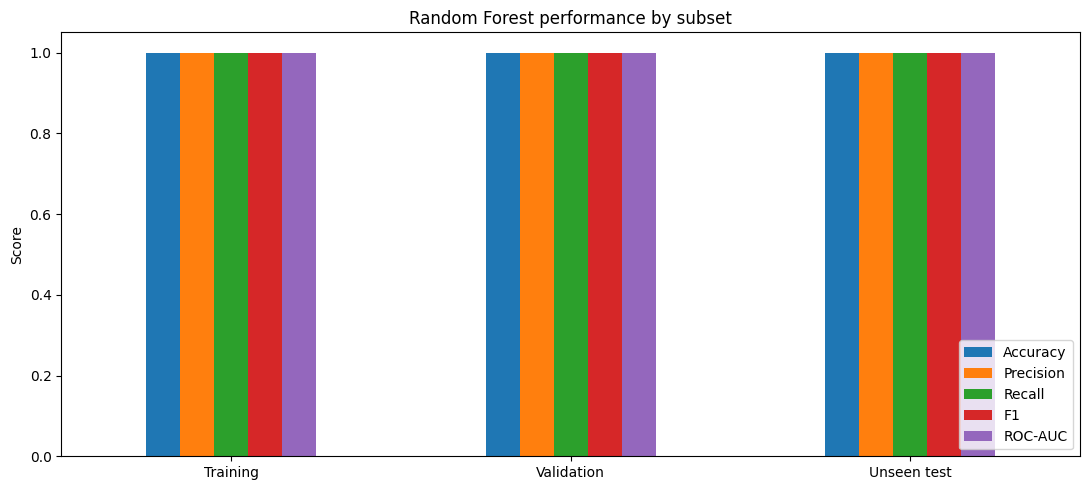

In [27]:
# Training metrics for comparison with validation and unseen test metrics.
y_train_pred = model.predict(X_train)
y_train_proba = model.predict_proba(X_train)[:, 1]

def metric_row(label, y_true, y_pred, y_proba):
    return {
        "subset": label,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

comparison = pd.DataFrame([
    metric_row("Training", y_train, y_train_pred, y_train_proba),
    metric_row("Validation", y_valid, y_valid_pred, y_valid_proba),
    metric_row("Unseen test", y_test, y_test_pred, y_test_proba),
]).set_index("subset")

(comparison.round(3))

ax = comparison.plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))
ax.set_title("Random Forest performance by subset")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "random_forest_performance by subset.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

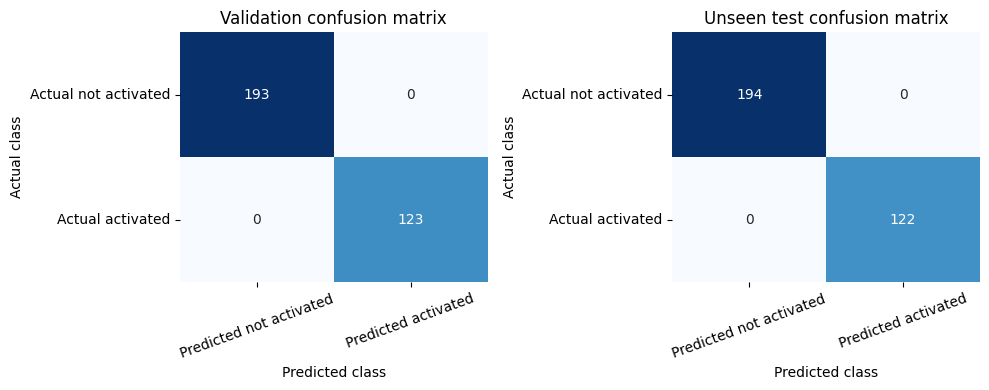

In [28]:
# Confusion matrices for validation and unseen test data.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, y_true, y_pred, title in [
    (axes[0], y_valid, y_valid_pred, "Validation confusion matrix"),
    (axes[1], y_test, y_test_pred, "Unseen test confusion matrix"),
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Predicted not activated", "Predicted activated"],
        yticklabels=["Actual not activated", "Actual activated"]
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.tick_params(axis="x", rotation=20)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()

plt.savefig(
    "Confusion matrices for validation and unseen test data.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

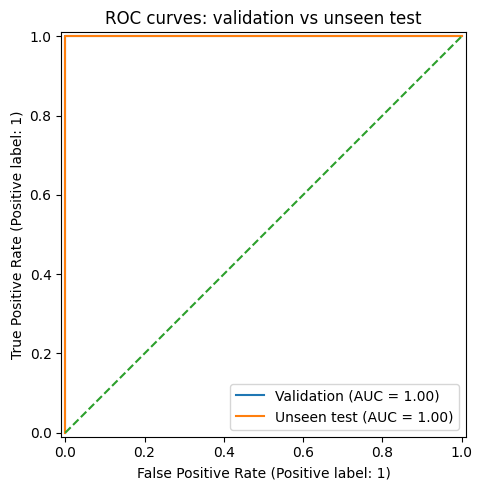

In [29]:
# ROC curves for validation and unseen test data.
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(
    y_valid, y_valid_proba, name="Validation", ax=ax
)
RocCurveDisplay.from_predictions(
    y_test, y_test_proba, name="Unseen test", ax=ax
)
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance baseline")
ax.set_title("ROC curves: validation vs unseen test")
plt.tight_layout()
plt.savefig(
    "ROC curves for validation and unseen test data.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

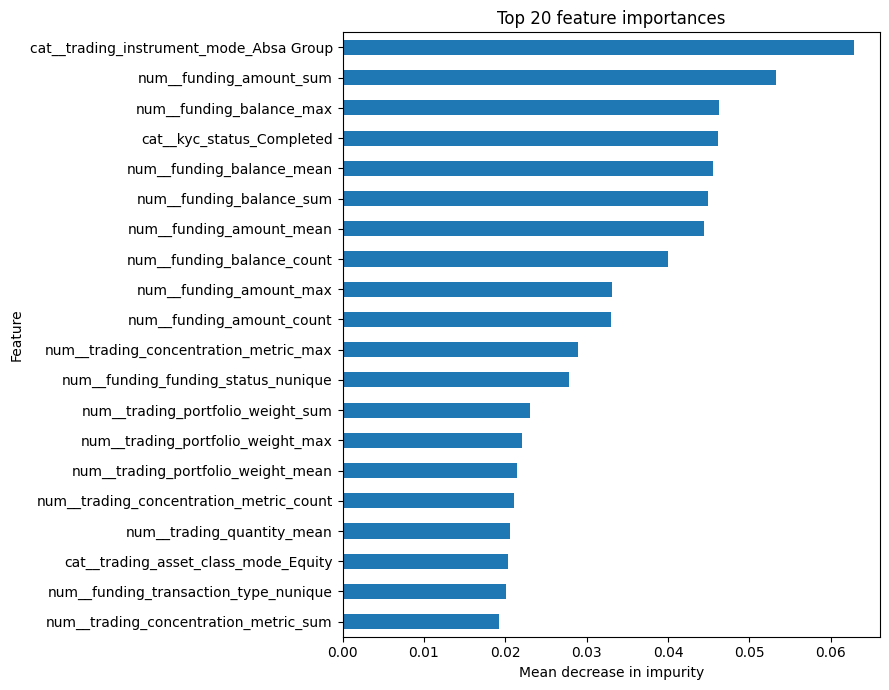

In [30]:
# Top 20 Random Forest feature importances.
fitted_preprocessor = model.named_steps["preprocessing"]
fitted_rf = model.named_steps["classifier"]

try:
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = pd.Series(
        fitted_rf.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False).head(20)

    ax = importances.sort_values().plot(
        kind="barh", figsize=(9, 7), title="Top 20 feature importances"
    )
    ax.set_xlabel("Mean decrease in impurity")
    ax.set_ylabel("Feature")
    plt.tight_layout()

    plt.savefig(
    "Top 20 Random Forest feature importances.png",
    dpi=300,
    bbox_inches="tight"
    )    
    plt.show()
except Exception as exc:
    print("Could not retrieve feature names for this version of scikit-learn:", exc)